In [1]:
import numpy as np
import cupy as cp
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from numpy.linalg import inv
import os

from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000

import skimage
from skimage.color import rgb2lab, lab2rgb

from numpy.random import random
from numpy.random import rand

from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf

import time

# Functions

In [2]:
def srgb_to_linsrgb(srgb):
    """Convert sRGB values to physically linear ones. The transformation is
    uniform in RGB, so *srgb* can be of any shape.
    *srgb* values should range between 0 and 1, inclusively.
    """
    gamma = ((srgb + 0.055) / 1.055)**2.4
    scale = srgb / 12.92
    return np.where(srgb > 0.04045, gamma, scale)


def linsrgb_to_srgb(linsrgb):
    """Convert physically linear RGB values into sRGB ones. The transform is
    uniform in the components, so *linsrgb* can be of any shape.
    *linsrgb* values should range between 0 and 1, inclusively.
    """
    # From Wikipedia, but easy analogue to the above.
    gamma = 1.055 * linsrgb**(1./2.4) - 0.055
    scale = linsrgb * 12.92
    return np.where(linsrgb > 0.0031308, gamma, scale)

In [3]:
def cal_delta_e_cie2000_lab(lab_src, lab_test):
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

def cal_delta_e_cie2000_rgb(rgb_src, rgb_test):
    
    lab_src = rgb2lab(rgb_src / 255.0)
    lab_test = rgb2lab(rgb_test / 255.0)
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
    
    # ignore gray
#     return errs[:-6]

    return errs

def rmse(errs):
    return np.sqrt(((errs) ** 2).mean())

In [4]:
def plot_diff(rgb1, rgb2, dump_file=None):
    
    errs = cal_delta_e_cie2000_rgb(rgb1, rgb2)
    
    plt.figure(figsize=(6, 14))
    plt.axis('off')
    plt.xlim(0, 30)
    plt.ylim(-2, 26)

    plt.annotate('c1.', (8, 25), fontsize = 20)
    plt.annotate('c2.', (16, 25), fontsize = 20)
    plt.annotate('CIEDE2000', (24, 25), fontsize = 20)

    plt.annotate('mean', (16, -1), fontsize = 20)
    plt.annotate('%.2f' %(np.mean(errs)), (26, -1), fontsize = 20)

    plt.annotate('rmse', (16, -2), fontsize = 20)
    plt.annotate('%.2f' %(rmse(errs)), (26, -2), fontsize = 20)
    
    for i in range(24):

        now_c1 = rgb1[i,:]
        now_c2 = rgb2[i,:]

        plt.scatter([10], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
        plt.scatter([18], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))

        plt.annotate('%.2f' %(errs[i]), (26, 24 - i - 0.2), fontsize = 20)
        
    if dump_file is not None:
        plt.savefig(dump_file)

    plt.show()

# Prepare data

In [5]:
# standard data

# 24 std - std24
# normal wli - wlis
# capsule wli - caps
# normal nbi - nbis

std24 = np.load('data_std.npy')
wlis = np.load('data_wli.npy')
nbis = np.load('data_nbi.npy')
caps = np.load('data_cap3.npy')

In [6]:
# adjust target NBI

nbis_adj = nbis.copy()

# nbis_adj = nbis_adj * 1.2

# nbis_adj[0:18, 0] = nbis_adj[0:18, 0] + 35
# nbis_adj[0:18, 1] = nbis_adj[0:18, 1] - 20
# nbis_adj[0:18, 2] = nbis_adj[0:18, 2] - 22

nbis_adj[nbis_adj>255] = 255
nbis_adj[nbis_adj<0] = 0

nbis_adj = nbis_adj.astype('uint8')

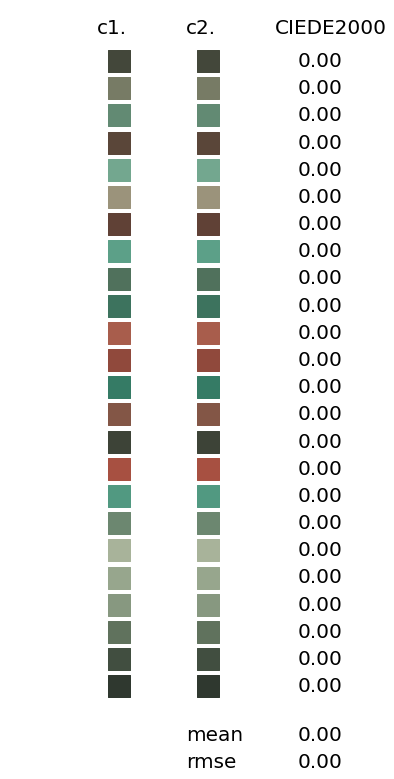

In [7]:
plot_diff(nbis, nbis_adj)

In [8]:
nbis = nbis_adj

# Training model

In [9]:
# define model and save

md_name = 'md_nbi'

model= keras.Sequential()
model.add(layers.Dense(units=24, input_dim=3, kernel_initializer='normal'))
model.add(layers.Dense(units=24))
model.add(layers.Dense(units=3))

# optimizer = keras.optimizers.Adam(learning_rate=0.0005)
# model.compile(loss=my_loss_fn, optimizer='Adam', metrics=['RootMeanSquaredError'], run_eagerly=True)
model.compile(loss='mean_squared_error', optimizer='Adam', metrics=['RootMeanSquaredError'])

model.save(md_name)

print(model.summary())

INFO:tensorflow:Assets written to: md_nbi\assets
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 24)                96        
                                                                 
 dense_1 (Dense)             (None, 24)                600       
                                                                 
 dense_2 (Dense)             (None, 3)                 75        
                                                                 
Total params: 771
Trainable params: 771
Non-trainable params: 0
_________________________________________________________________
None


In [10]:
# assign train data

train_x = wlis / 255
train_y = nbis / 255

In [11]:
# define weight file

weight_file = 'nor_wli.hdf5'

In [12]:
mcp_save = tf.keras.callbacks.ModelCheckpoint(weight_file, save_best_only=True, monitor='loss', mode='min')

history= model.fit(x=train_x, y=train_y, epochs=200, batch_size=5, callbacks=[mcp_save], verbose=0)

model.load_weights(weight_file)

In [13]:
scores = model.evaluate(train_x, train_y) 

1/1 [==============================] - 0s 188ms/step - loss: 5.2748e-04 - root_mean_squared_error: 0.0230


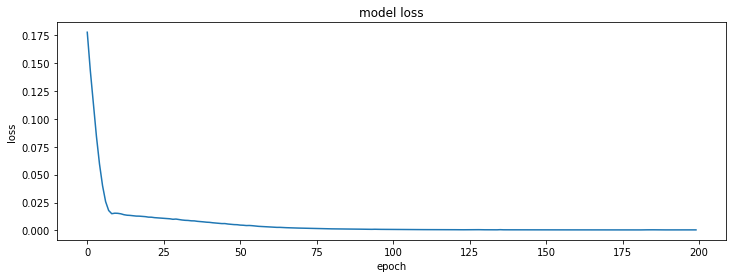

In [14]:
plt.figure(figsize=(12, 4))

#  Accuracy
# plt.subplot(1,2,1)
# plt.plot(history.history['accuracy'])
# plt.title('model accuracy')
# plt.ylabel('accuracy')
# plt.xlabel('epoch')

# Loss
# plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.show()

# Transfer test color

In [15]:
md_name = 'md_nbi'
weight_file = 'nor_wli.hdf5'

nbi_model = tf.keras.models.load_model(md_name)
nbi_model.load_weights(weight_file)

In [16]:
sim_nbis = (nbi_model.predict(wlis/255)*255).astype('uint8')

1/1 [==============================] - 0s 141ms/step


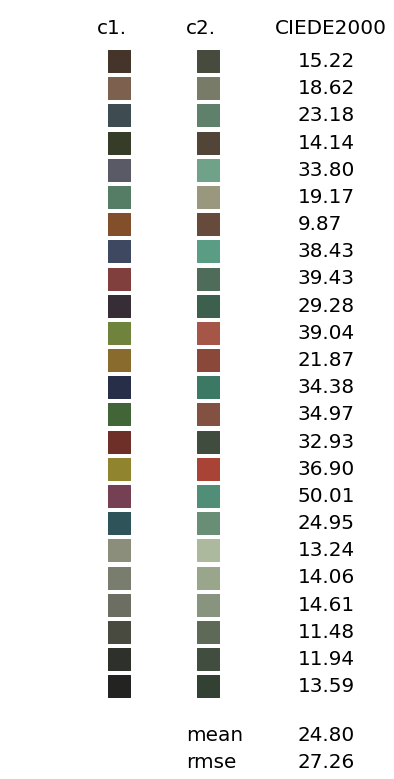

In [17]:
plot_diff(wlis, sim_nbis)

In [1]:
plot_diff(nbis, sim_nbis)
im.save(plot_diff)

NameError: name 'plot_diff' is not defined

In [19]:
errs = cal_delta_e_cie2000_rgb(nbis, sim_nbis)

In [20]:
np.savetxt("dump_nbis.csv", nbis, delimiter=",")
np.savetxt("dump_sim_nbis.csv", sim_nbis, delimiter=",")
np.savetxt("dump_errs.csv", errs, delimiter=",")

# Transfer image

In [21]:
def sToneCurve(frame):
    look_up_table = np.zeros((256,1), dtype = 'uint8')
    for i in range(256):
        look_up_table[i][0] = 255 * (np.sin(np.pi * (i/255 - 1/2)) + 1) / 2
    return cv2.LUT(frame, look_up_table)

def color_transfer(src_data, gain = 1.2):
     
    data_shape = src_data.shape
    
    tar_data = src_data.reshape(-1, data_shape[-1])

    tar_data = tar_data / 255
    
    tar_data = nbi_model.predict(tar_data, batch_size = tar_data.shape[0])

    tar_data = tar_data * 255
    
    tar_data = tar_data * gain
    
    tar_data[tar_data<0] = 0
    tar_data[tar_data>255] = 255
    
    tar_data = tar_data.astype('uint8')
    tar_data = tar_data.reshape(data_shape)
    
    return tar_data

In [22]:
img = cv2.imread('samp_01.jpg')

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

rep_img = color_transfer(img)

rep_img = sToneCurve(rep_img)

1/1 [==============================] - 0s 80ms/step


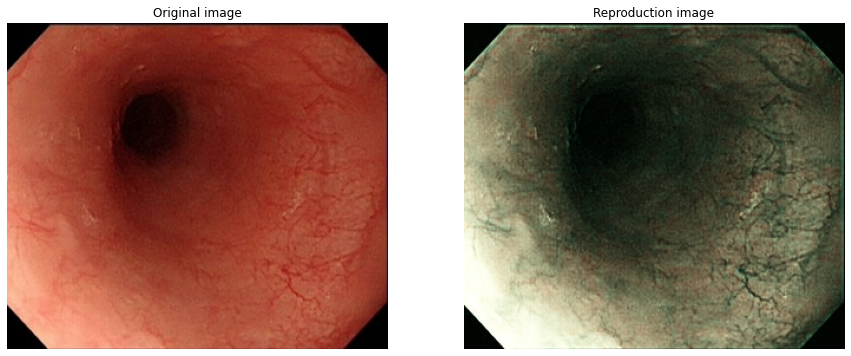

In [23]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(rep_img)
plt.title('Reproduction image')
plt.axis('off')

plt.show()

In [24]:
tar_img = cv2.cvtColor(rep_img, cv2.COLOR_BGR2RGB)
cv2.imwrite('samp_01_rep.jpg', tar_img)

True

# Transfer by matrix operation

In [55]:
weights = nbi_model.get_weights()

def predict(img):
    tar_img = np.dot((img/255), weights[0]) + weights[1]
    tar_img = np.dot(tar_img, weights[2]) + weights[3]
    tar_img = np.dot(tar_img, weights[4]) + weights[5]
    return (tar_img * 255).astype('uint8')

In [56]:
sim_nbis = predict(wlis)

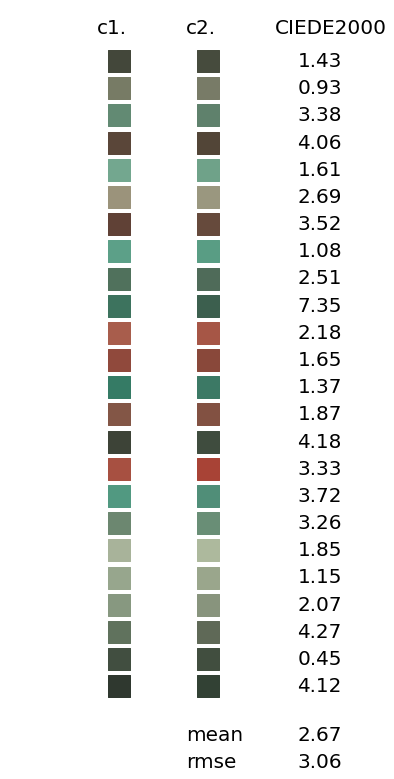

In [57]:
plot_diff(nbis, sim_nbis)

# Save weight for create LUT tabel

In [60]:
weights = nbi_model.get_weights()

for i in range(len(weights)):
    np.save('nor_wli_weight%d.npy'%i, weights[i])